# TinyVCM: Raspberry Pi 4 voice-command training report

**Fresh public-data training • Independent intent and parameter models • Executed audio tests**

This phase builds a local acoustic voice-command model (VCM) and a separately trained parameter speech recognizer (ASR). The VCM alone selects the action. An optional ASR receives the retained audio tail and fills parameters. Both trained checkpoints, ONNX exports, the microphone-selectable CLI, and per-recording test results are in this `model/` folder.

**This is a research baseline with measured shortcomings.** The intent model has limited command coverage and conservative rejection; it does not meet the original accuracy goal. No Raspberry Pi 4 microphone or board benchmark has been performed. The small Philippine English read-speech diagnostic is not a supported-command accent benchmark. The early trigger is a causal prediction, not a verified parameter boundary.

This notebook executes analysis and verification from saved artifacts. It does not download datasets or silently retrain models. Reproduction commands are at the end; detailed design refinements are in [IMPLEMENTATION_NOTES.md](IMPLEMENTATION_NOTES.md).

In [1]:
from pathlib import Path
import json, hashlib, sys
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio
ROOT = Path.cwd()
if not (ROOT / 'reports/vcm_metrics.json').exists():
    ROOT = ROOT / 'model'
sys.path.insert(0, str(ROOT))
from tinyvcm.data import read_jsonl
def read(name):
    return json.loads((ROOT / 'reports' / name).read_text(encoding='utf-8'))
def table(headers, rows):
    def cell(value):
        return str(value).replace('|', chr(92) + '|').replace('\n', ' ')
    display(Markdown('| ' + ' | '.join(headers) + ' |\n|' + '|'.join(['---'] * len(headers)) + '|\n' + '\n'.join('| ' + ' | '.join(map(cell, row)) + ' |' for row in rows)))
def pct(value):
    return f'{value:.1%}'
def figure(name):
    folder = ROOT / 'reports/figures'
    folder.mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(folder / name, dpi=150, bbox_inches='tight')
    plt.show()
plt.rcParams.update({'figure.figsize': (10, 4.5), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
vcm = read('vcm_metrics.json')
asr = read('asr_metrics.json')
voice = read('voice_suite_metrics.json')
joint = read('joint_metrics.json')
accent = read('accent_metrics.json')
bundle = json.loads((ROOT / 'artifacts/tinyvcm/bundle.json').read_text())
test = vcm['test']['fp32']
supported_count = sum(r['samples'] for label, r in test['per_class'].items() if label != 'UNKNOWN')
supported_accuracy = sum(r['correct'] for label, r in test['per_class'].items() if label != 'UNKNOWN') / supported_count
table(['Result', 'Measured value', 'Meaning'], [
    ['VCM test recordings', test['samples'], 'Untouched curated SLURP-real test cohort'],
    ['Raw intent accuracy / macro F1', f"{pct(test['accuracy'])} / {test['macro_f1']:.3f}", 'Before confidence rejection'],
    ['Supported-label raw accuracy', pct(supported_accuracy), f'{supported_count} supported-command recordings, excluding UNKNOWN'],
    ['Accepted-intent precision', pct(test['accepted_precision']), f"{test['correct_accepted']} correct of {test['accepted']} accepted labels; parameters are not scored here"],
    ['Supported-command recall after rejection', pct(test['positive_recall_after_rejection']), 'Missed/rejected supported commands count against recall'],
    ['Unknown false-accept rate', pct(test['unknown_false_accept_rate']), f"{test['unknown_false_accepts']} of {test['unknown_samples']} unsupported test recordings"],
    ['Early-trigger precision / positive recall', f"{pct(vcm['test']['early_fp32']['precision'])} / {pct(vcm['test']['early_fp32']['positive_trigger_recall'])}", 'Provisional VCM events, before final validation'],
    ['ASR SLURP test WER', pct(asr['SLURP-real']['wer']), 'Lower is better; full utterances, not gold parameter tails'],
    ['Complete-frame rate on resolvable references', pct(joint['fp32']['exact_frame_rate']), f"{joint['fp32']['exact_frames']} of {joint['fp32']['reference_parser_eligible']} silver-reference frames; rejections count as failures"],
    ['Pi 4 physical test', 'NOT RUN', 'Use the supplied benchmark and selectable-microphone CLI on the board'],
])

| Result | Measured value | Meaning |
|---|---|---|
| VCM test recordings | 3116 | Untouched curated SLURP-real test cohort |
| Raw intent accuracy / macro F1 | 74.1% / 0.619 | Before confidence rejection |
| Supported-label raw accuracy | 71.2% | 1558 supported-command recordings, excluding UNKNOWN |
| Accepted-intent precision | 96.4% | 267 correct of 277 accepted labels; parameters are not scored here |
| Supported-command recall after rejection | 17.1% | Missed/rejected supported commands count against recall |
| Unknown false-accept rate | 0.6% | 9 of 1558 unsupported test recordings |
| Early-trigger precision / positive recall | 91.6% / 18.2% | Provisional VCM events, before final validation |
| ASR SLURP test WER | 48.4% | Lower is better; full utterances, not gold parameter tails |
| Complete-frame rate on resolvable references | 10.2% | 150 of 1466 silver-reference frames; rejections count as failures |
| Pi 4 physical test | NOT RUN | Use the supplied benchmark and selectable-microphone CLI on the board |

## 1. Architecture and the user-requested separation

```text
microphone / WAV → 16 kHz PCM → fixed log-mel frontend
                                     │
                       causal VCM → provisional command event
                                     │
                  retained audio from trigger minus 500 ms
                                     │
                 final VCM confidence/agreement check
                                     │
                  optional independent character-CTC ASR
                                     │
               argument parser + editable names/aliases
                                     │
       accepted / rejected / needs_parameters / needs_clarification
```

VCM training uses audio and curated intent labels derived from the dataset's human text/intent annotations. It does not load an ASR encoder, use ASR-generated transcripts, run forced alignment, or decode words. ASR acoustic training starts from random weights on LibriSpeech. It then adapts to assistant speech, starting from its own acoustic checkpoint. Reusing the `FrameNorm` Python layer implementation is code reuse, not shared trained parameters.

The early command event is provisional. At the utterance endpoint, the final VCM score must pass its confidence threshold and agree with any early event before a parameter tail reaches ASR. The command is held fixed when parsing ASR output: for example, `POWER_ON` fixes the Boolean to `true`. Catalog names are runtime arguments, not intent classes. Matching is exact after normalization and ambiguous/missing names require clarification. No device-control or music-service requests are sent.

### Difference from the proposed boundary model

Public SLURP annotations provide token spans but no verified time boundaries. This baseline therefore has **no WAIT/readiness head, no learned boundary detector, and no boundary-supervised VCM loss**. Its causal classifier is trained on complete utterance labels. Stable prefix predictions are tested experimentally. The look-back can lose early parameter sounds or include command words; the report measures the resulting pipeline. `data/annotations/review_queue.jsonl` contains existing public clips awaiting verified timing annotation. The ASR is trained on full speech, not invented parameter crops.

## 2. Public data, provenance, and license record

- [SLURP upstream](https://github.com/pswietojanski/slurp): assistant speech and human text/intent/entity annotations. Text is CC BY 4.0; real audio is CC BY-NC 4.0. Authoritative IDs and annotations are pinned to an upstream revision. Real audio is transported through a pinned [qmeeus/slurp mirror](https://huggingface.co/datasets/qmeeus/slurp) with LFS SHA-256 checks. Synthetic recordings are excluded.
- [LibriSpeech / OpenSLR 12](https://www.openslr.org/12/): CC BY 4.0 read English speech. `train-clean-100`, `dev-clean`, and `test-clean` were downloaded and checked against publisher MD5 values, with local SHA-256 values also recorded. Durations above 20 seconds are excluded for this bounded experiment.
- [Speech Accent Archive](https://accent.gmu.edu/language/tagalog/): ten unchanged public recordings used only for an external read-prompt diagnostic. Attribution: Steven H. Weinberger and Matthew C. Kelley, George Mason University; CC BY-NC-SA 4.0. Publisher birthplace metadata identifies the selected Philippine readers. These clips do not enter training, model selection, or threshold calibration.

These are local research artifacts. Preserve the source attributions and data license terms when sharing audio. The downloadable UP-DSP multilingual archive and a gated Kenya/Philippines conversation corpus are recorded as unacquired sources in the accent audit; their existence is not counted as training evidence.

SLURP scoring uses publisher-supplied text shared across microphone views. This run did not manually re-transcribe the corpus or filter examples using ASR-generated transcript-quality scores. Source references can differ from exact spoken wording; no measured share of the recognition error is attributed to that possibility.

In [2]:
sources = []
for path in sorted((ROOT / 'data/manifests').glob('*.source.json')):
    item = json.loads(path.read_text())
    sources.append([path.name, item.get('revision', item.get('source', 'see ledger')), len(item.get('files', []))])
table(['Ledger', 'Pinned revision / source', 'Files'], sources)
vrows = read_jsonl(ROOT / 'data/manifests/vcm.jsonl')
arows = read_jsonl(ROOT / 'data/manifests/asr.jsonl')
data_rows = []
for task, rows in [('VCM', vrows), ('ASR', arows)]:
    for source in sorted({r['source'] for r in rows}):
        for split in ['train', 'dev', 'calibration', 'test']:
            selected = [r for r in rows if r['source'] == source and r['split'] == split]
            if selected:
                data_rows.append([task, source, split, len(selected), f"{sum(r['duration'] for r in selected)/3600:.2f}", len({r['speaker_id'] for r in selected})])
table(['Task manifest', 'Source', 'Split', 'Clips', 'Hours', 'Speaker IDs'], data_rows)
display(Markdown('ASR adaptation uses all SLURP training rows plus a deterministic 10% subset of LibriSpeech training rows. Its exact run counts below are the authoritative training totals. The task manifests overlap: these counts must not be added to claim unique collected hours.'))

| Ledger | Pinned revision / source | Files |
|---|---|---|
| librispeech.source.json | librispeech | 3 |
| slurp.source.json | 8eb16545762be97ace75334109d73824217311f1 | 4 |
| slurp_audio_mirror.source.json | 91b0abfee2e735282967ee00d631d6d5f0fb7ff9 | 9 |

| Task manifest | Source | Split | Clips | Hours | Speaker IDs |
|---|---|---|---|---|---|
| VCM | SLURP-real | train | 11310 | 8.48 | 147 |
| VCM | SLURP-real | dev | 1378 | 1.02 | 127 |
| VCM | SLURP-real | calibration | 745 | 0.56 | 114 |
| VCM | SLURP-real | test | 3116 | 2.35 | 135 |
| ASR | LibriSpeech | train | 28538 | 100.58 | 251 |
| ASR | LibriSpeech | dev | 2642 | 4.97 | 40 |
| ASR | LibriSpeech | test | 2528 | 4.79 | 40 |
| ASR | SLURP-real | train | 50510 | 40.03 | 166 |
| ASR | SLURP-real | dev | 6486 | 5.15 | 137 |
| ASR | SLURP-real | test | 13019 | 10.15 | 142 |

ASR adaptation uses all SLURP training rows plus a deterministic 10% subset of LibriSpeech training rows. Its exact run counts below are the authoritative training totals. The task manifests overlap: these counts must not be added to claim unique collected hours.

## 3. Leakage audit and curation

The audit found microphone views of the same recording crossing official SLURP source partitions, as well as a recording with inconsistent text. All affected views are quarantined. Remaining official source partitions are retained. Connected prompt/microphone families stay together when splitting development into model-selection and calibration partitions.

**The source splits share speakers.** This report does not describe them as speaker-disjoint. Cluster intervals account for paired recordings but do not remove shared-speaker dependence. A stronger speaker-disjoint study remains necessary. Unknown examples are deterministically sampled into a curated cohort; the scores are not an official whole-SLURP benchmark.

Training coverage determines the first label inventory: at least 40 training clips and 10 combined development/calibration clips. This is an inclusion rule, not statistical adequacy. The rarest commands have very small validation sets. Labels are conservatively mapped from intent plus human text; alarms are not renamed timers, and conflicting on/off phrases become unknown. Rule-based curation can still contain annotation mistakes.

In [3]:
audit = read('split_audit.json')
quarantine = read('leakage_quarantine.json')
coverage = read('coverage.json')
display(Markdown('**Quarantine summary:**'))
display({k: v for k, v in quarantine.items() if not isinstance(v, list) or len(v) < 8})
display(Markdown('Detailed excluded IDs are in `reports/leakage_quarantine.json`.'))
# Recheck actual VCM ID and microphone-group separation, not just a saved status flag.
sets = {s: {r['id'] for r in vrows if r['split'] == s} for s in ['train','dev','calibration','test']}
pairs = {s: {r['paired_group'] for r in vrows if r['split'] == s} for s in sets}
for i, left in enumerate(sets):
    for right in list(sets)[i+1:]:
        assert not (sets[left] & sets[right]), (left, right, 'duplicate ID')
        assert not (pairs[left] & pairs[right]), (left, right, 'paired leakage')
table(['Command', 'Train', 'Dev', 'Calibration', 'Test'], [[c, *[sum(r['command']==c and r['split']==s for r in vrows) for s in ['train','dev','calibration','test']]] for c in vcm['labels']])
display(Markdown('**Unsupported acoustic labels:** BRIGHTNESS_SET, VOLUME_SET, MEDIA_PAUSE, MEDIA_STOP, TIMER_SET. Parser support for an argument type does not imply that its VCM class was trained. MEDIA_RESUME has no examples in the model-selection development partition and must be interpreted cautiously.'))

**Quarantine summary:**

{'conflicting_transcript_recording_ids': ['slurp/audio-1502309360-headset.flac'],
 'removed_records': 172,
 'original_records': 72384,
 'retained_records': 72212,
 'policy': 'Remove all views of leaking pairs; preserve original source splits on retained rows.'}

Detailed excluded IDs are in `reports/leakage_quarantine.json`.

| Command | Train | Dev | Calibration | Test |
|---|---|---|---|---|
| UNKNOWN | 5655 | 689 | 500 | 1558 |
| POWER_ON | 251 | 24 | 3 | 32 |
| POWER_OFF | 864 | 56 | 19 | 237 |
| BRIGHTNESS_UP | 232 | 29 | 7 | 59 |
| BRIGHTNESS_DOWN | 412 | 29 | 11 | 130 |
| COLOR_SET | 308 | 38 | 23 | 69 |
| MEDIA_PLAY | 1892 | 306 | 102 | 518 |
| MEDIA_RESUME | 108 | 0 | 10 | 14 |
| TIME_QUERY | 912 | 107 | 38 | 347 |
| DATE_QUERY | 676 | 100 | 32 | 152 |

**Unsupported acoustic labels:** BRIGHTNESS_SET, VOLUME_SET, MEDIA_PAUSE, MEDIA_STOP, TIMER_SET. Parser support for an argument type does not imply that its VCM class was trained. MEDIA_RESUME has no examples in the model-selection development partition and must be interpreted cautiously.

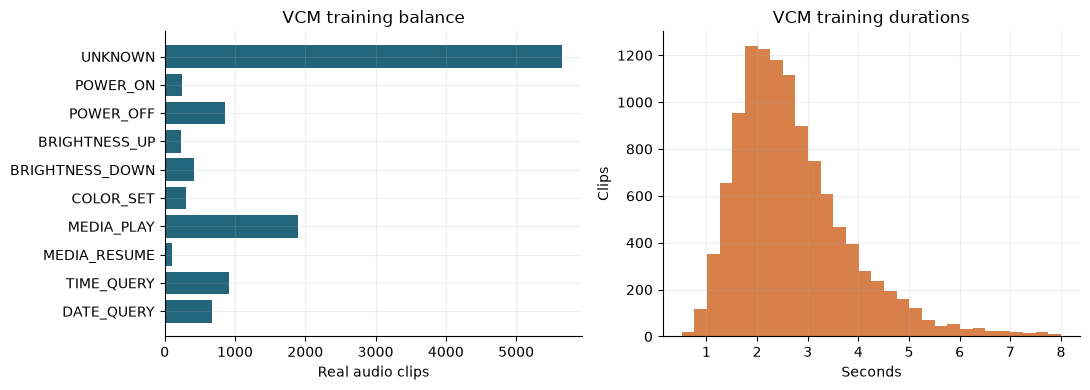

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = vcm['labels']
counts = [sum(r['command']==c and r['split']=='train' for r in vrows) for c in labels]
axes[0].barh(labels, counts, color='#23667b')
axes[0].invert_yaxis()
axes[0].set_title('VCM training balance')
axes[0].set_xlabel('Real audio clips')
axes[1].hist([r['duration'] for r in vrows if r['split']=='train'], bins=30, color='#d8804a')
axes[1].set_title('VCM training durations')
axes[1].set_xlabel('Seconds'); axes[1].set_ylabel('Clips')
figure('data_coverage.png')

## 4. Signal processing and model sizes

Audio is explicitly converted to mono 16 kHz. The fixed frontend uses a 400-sample periodic Hann window (25 ms), 160-sample hop (10 ms), FFT size 512, 40 HTK-scale triangular filters from 60 to 7,600 Hz, natural-log power with floor 1e-8, and **no centered padding**. Per-mel normalization statistics are computed from training frames only. Training, WAV replay, and live input share this implementation.

The VCM uses left-padded causal convolution, per-frame channel normalization, depthwise/pointwise residual blocks, and cumulative pooling. Explicit convolution caches and pooling state permit chunked inference. The selected model's encoded feature context is 0.865 seconds; pooled decisions retain evidence over the entire prefix. Causality means a future audio suffix cannot change an earlier score; it does not mean an early score is correct.

ASR uses a strided convolution followed by six noncausal residual blocks with depthwise/pointwise convolution and a character CTC head. The assistant adaptation masks padded batch positions so valid frames match a single-clip deployment call. Greedy decoding has no language model. Its alphabet contains blank, a space, a–z, and apostrophe. Literal-digit/empty supervision is excluded when normalization cannot represent it reliably; spoken number words remain available.

In [5]:
table(['Model', 'Parameters', 'FP32 ONNX MiB', 'INT8 ONNX MiB'], [[task.upper(), f"{bundle[task]['parameters']:,}", f"{bundle['files'][task+'.fp32.onnx']['bytes']/2**20:.3f}", f"{bundle['files'][task+'.int8.onnx']['bytes']/2**20:.3f}"] for task in ['vcm','asr']])
table(['Export contract', 'Value'], [['VCM streaming state bytes', bundle['vcm']['state_bytes']], ['VCM FP32 torch/ONNX maximum logit error', bundle['vcm']['fp32_torch_onnx_max_error']], ['VCM streaming/offline maximum logit error', bundle['vcm']['fp32_stream_offline_max_error']], ['ASR FP32 torch/ONNX maximum logit error', bundle['asr']['fp32_torch_onnx_max_error']]])
for name, facts in bundle['files'].items():
    assert hashlib.sha256((ROOT / 'artifacts/tinyvcm' / name).read_bytes()).hexdigest() == facts['sha256']
print('All exported model hashes verified against bundle.json.')

| Model | Parameters | FP32 ONNX MiB | INT8 ONNX MiB |
|---|---|---|---|
| VCM | 205,066 | 0.825 | 0.307 |
| ASR | 1,321,757 | 5.074 | 1.431 |

| Export contract | Value |
|---|---|
| VCM streaming state bytes | 42116 |
| VCM FP32 torch/ONNX maximum logit error | 3.814697265625e-06 |
| VCM streaming/offline maximum logit error | 2.384185791015625e-06 |
| ASR FP32 torch/ONNX maximum logit error | 5.221366882324219e-05 |

All exported model hashes verified against bundle.json.


## 5. Fresh training and development-only selection

All training used seed 17, AdamW, gradient-norm clipping at 1.0, a warm-up/cosine schedule, and length-bucketed batches with a 16,000-frame budget. Feature augmentation applies an additive log-feature gain offset and time/frequency masks; no real room impulse responses are claimed. VCM uses inverse-square-root class weights and 0.03 label smoothing. ASR uses CTC loss. Full hyperparameters, training-manifest hashes, normalization, GPU, and versions are saved in each run.

Two VCM candidates were selected by development macro F1, before final voice testing. Early stopping has patience eight. A separate calibration partition selects final confidence and early-trigger thresholds. The ASR first learns acoustics from LibriSpeech, then adapts to assistant speech. Its checkpoint criterion is development WER. There is no validation/test audio in gradient updates.

| Run | Train / dev clips | Train hours | Epochs | Parameters | Recorded epoch time (min) |
|---|---|---|---|---|---|
| vcm_seed17 | 11310 / 1378 | 8.48 | 50 | 205,066 | 3.3 |
| vcm_context_seed17 | 11310 / 1378 | 8.48 | 26 | 443,914 | 2.0 |
| asr_acoustic_seed17 | 28538 / 2642 | 100.58 | 40 | 1,321,757 | 32.3 |
| asr_commands_seed17 | 53344 / 6486 | 49.99 | 30 | 1,321,757 | 17.4 |

{'criterion': 'highest development macro F1; test never used',
 'candidates': [{'run': 'vcm_seed17',
   'epoch': 48,
   'loss': 0.807497424034318,
   'accuracy': 0.7518142235123367,
   'macro_f1': 0.6419892667192241,
   'samples': 1378},
  {'run': 'vcm_context_seed17',
   'epoch': 18,
   'loss': 0.7109341505476975,
   'accuracy': 0.762699564586357,
   'macro_f1': 0.6382384576287816,
   'samples': 1378}],
 'selected': {'run': 'vcm_seed17',
  'epoch': 48,
  'loss': 0.807497424034318,
  'accuracy': 0.7518142235123367,
  'macro_f1': 0.6419892667192241,
  'samples': 1378}}

Assistant adaptation resumed after an epoch checkpoint to enable a bounded RAM feature cache after measured small-file I/O stalls. Weights and optimizer were restored; dropout RNG continuation is not bitwise identical.

[{'resumed_from_epoch': 1,
  'feature_cache_mib': 6144,
  'utc': '2026-09-15T10:43:47Z',
  'rng_note': 'Weights and optimizer restored; initialization seeds reset, so dropout RNG continuation is not bitwise identical.'}]

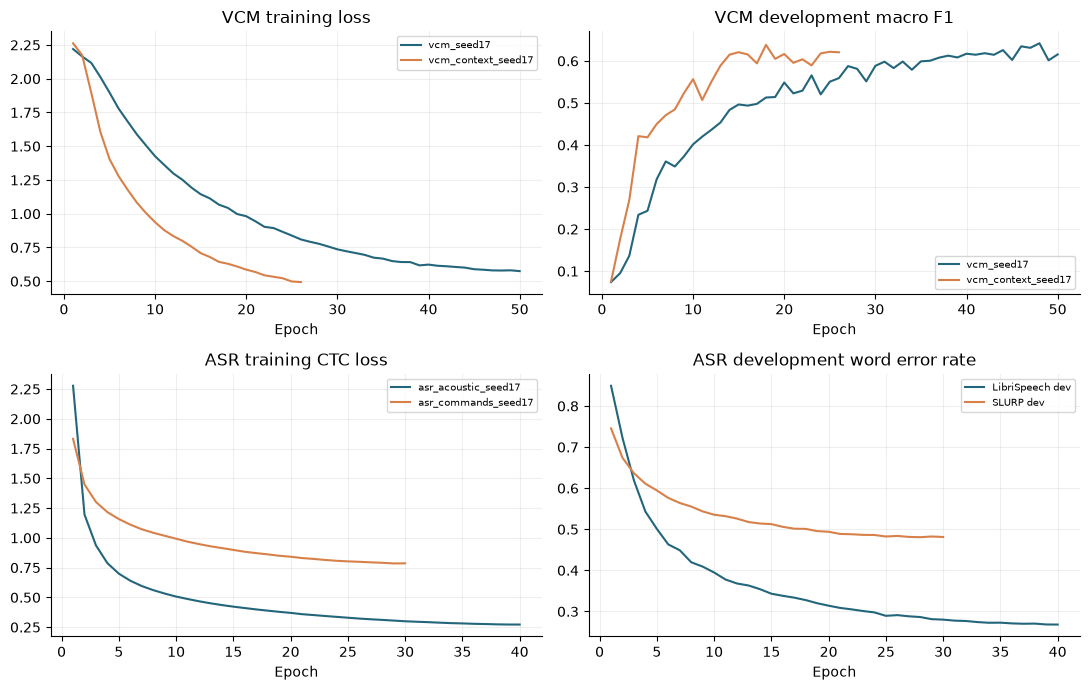

ASR development curves use different corpora: LibriSpeech during acoustic training and SLURP during assistant adaptation. Their vertical gap is not a before/after comparison on the same test set.

In [6]:
run_names = ['vcm_seed17','vcm_context_seed17','asr_acoustic_seed17','asr_commands_seed17']
histories = {name: read_jsonl(ROOT / 'runs' / name / 'history.jsonl') for name in run_names}
configs = {name: json.loads((ROOT / 'runs' / name / 'config.json').read_text()) for name in run_names}
completions = {name: json.loads((ROOT / 'runs' / name / 'complete.json').read_text()) for name in run_names}
table(['Run', 'Train / dev clips', 'Train hours', 'Epochs', 'Parameters', 'Recorded epoch time (min)'], [[name, f"{configs[name]['train_samples']} / {configs[name]['dev_samples']}", f"{configs[name]['train_hours']:.2f}", completions[name]['epochs'], f"{configs[name]['parameters']:,}", f"{sum(r['seconds'] for r in histories[name])/60:.1f}"] for name in run_names])
display(read('model_selection.json'))
restart_file = ROOT / 'runs/asr_commands_seed17/restarts.jsonl'
if restart_file.exists():
    display(Markdown('Assistant adaptation resumed after an epoch checkpoint to enable a bounded RAM feature cache after measured small-file I/O stalls. Weights and optimizer were restored; dropout RNG continuation is not bitwise identical.'))
    display(read_jsonl(restart_file))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for name, color in zip(run_names[:2], ['#23667b','#d8804a']):
    h = histories[name]
    axes[0,0].plot([r['epoch'] for r in h], [r['training_loss'] for r in h], label=name, color=color)
    axes[0,1].plot([r['epoch'] for r in h], [r['validation']['macro_f1'] for r in h], label=name, color=color)
for name, color in zip(run_names[2:], ['#23667b','#d8804a']):
    h = histories[name]
    axes[1,0].plot([r['epoch'] for r in h], [r['training_loss'] for r in h], label=name, color=color)
    dev_source = 'LibriSpeech dev' if name == 'asr_acoustic_seed17' else 'SLURP dev'
    axes[1,1].plot([r['epoch'] for r in h], [r['validation']['wer'] for r in h], label=dev_source, color=color)
for ax, title in zip(axes.flat, ['VCM training loss','VCM development macro F1','ASR training CTC loss','ASR development word error rate']):
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend(fontsize=7)
figure('training_curves.png')
display(Markdown('ASR development curves use different corpora: LibriSpeech during acoustic training and SLURP during assistant adaptation. Their vertical gap is not a before/after comparison on the same test set.'))

## 6. Final voice-command test and the rejection tradeoff

The raw classifier is tested on all held-out cohort recordings using CPU ONNX inference. Accuracy is the fraction of correct intent labels; macro F1 gives each label equal importance among labels with support. The confidence threshold is then applied. Accepted-label precision is **not** end-to-end command-frame accuracy: optional ASR, target matching, missing parameters, and retracted early events can still prevent completion.

Threshold selection maximizes correct accepted commands while constraining calibration unknown false accepts to at most 1% and accepted precision to at least 95%. Report coverage alongside precision: rejecting most inputs can satisfy the precision target without making the assistant useful. The final test is never used to lower a threshold or choose a model.

| Variant | Raw accuracy | Macro F1 | Accepted precision | Positive recall | Unknown false accepts |
|---|---|---|---|---|---|
| fp32 | 74.1% | 0.619 | 96.4% | 17.1% | 9/1558 |
| int8 | 73.7% | 0.619 | 97.1% | 17.0% | 7/1558 |

FP32 accuracy interval, paired-recording cluster bootstrap: 72.5%–75.8%; 2383 groups.


| Label | Test clips | Correct | Recall | F1 |
|---|---|---|---|---|
| UNKNOWN | 1558 | 1200 | 77.0% | 0.786 |
| POWER_ON | 32 | 13 | 40.6% | 0.366 |
| POWER_OFF | 237 | 168 | 70.9% | 0.737 |
| BRIGHTNESS_UP | 59 | 36 | 61.0% | 0.511 |
| BRIGHTNESS_DOWN | 130 | 98 | 75.4% | 0.698 |
| COLOR_SET | 69 | 38 | 55.1% | 0.490 |
| MEDIA_PLAY | 518 | 373 | 72.0% | 0.730 |
| MEDIA_RESUME | 14 | 11 | 78.6% | 0.449 |
| TIME_QUERY | 347 | 273 | 78.7% | 0.791 |
| DATE_QUERY | 152 | 99 | 65.1% | 0.635 |

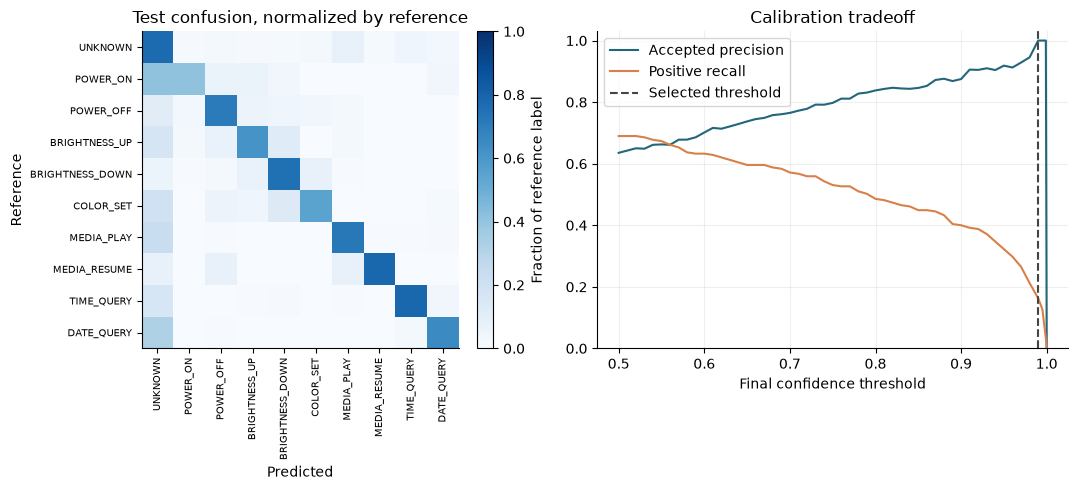

In [7]:
cal = read('threshold_calibration.json')
table(['Variant', 'Raw accuracy', 'Macro F1', 'Accepted precision', 'Positive recall', 'Unknown false accepts'], [[variant, pct(vcm['test'][variant]['accuracy']), f"{vcm['test'][variant]['macro_f1']:.3f}", pct(vcm['test'][variant]['accepted_precision']), pct(vcm['test'][variant]['positive_recall_after_rejection']), f"{vcm['test'][variant]['unknown_false_accepts']}/{vcm['test'][variant]['unknown_samples']}"] for variant in ['fp32','int8']])
interval = test['accuracy_interval']
print(f"FP32 accuracy interval, paired-recording cluster bootstrap: {interval['lower']:.1%}–{interval['upper']:.1%}; {interval['groups']} groups.")
table(['Label', 'Test clips', 'Correct', 'Recall', 'F1'], [[label, facts['samples'], facts['correct'], pct(facts['recall']), f"{facts['f1']:.3f}"] for label, facts in test['per_class'].items()])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
matrix = np.asarray(test['confusion'], dtype=float)
normalized_confusion = matrix / np.maximum(1, matrix.sum(axis=1, keepdims=True))
im = axes[0].imshow(normalized_confusion, vmin=0, vmax=1, cmap='Blues')
fig.colorbar(im, ax=axes[0], fraction=.046, pad=.04, label='Fraction of reference label')
axes[0].set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
axes[0].set_yticks(range(len(labels)), labels, fontsize=7)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Reference'); axes[0].set_title('Test confusion, normalized by reference')
axes[0].grid(False)
rows = cal['final_table']
axes[1].plot([r['threshold'] for r in rows], [r['accepted_precision'] for r in rows], label='Accepted precision', color='#23667b')
axes[1].plot([r['threshold'] for r in rows], [r['positive_recall_after_rejection'] for r in rows], label='Positive recall', color='#d8804a')
axes[1].axvline(bundle['routing']['acceptance_threshold'], color='#444444', linestyle='--', label='Selected threshold')
axes[1].set_ylim(0,1.03); axes[1].set_xlabel('Final confidence threshold'); axes[1].set_title('Calibration tradeoff'); axes[1].legend()
figure('confusion_and_rejection.png')

## 7. Early intent events and parameter slices

Prefixes are evaluated every four feature frames (40 ms). A trigger requires three consecutive confident chunks and at least 500 ms of audio. Threshold calibration constrains wrong-trigger frequency, then maximizes correct early events. The live CLI checks newly accumulated frames about every 160 ms and retains 80 ms at the resampler edge; reported audio timestamps do not include that scheduling delay.

The prefix test computes all causal prefix logits from the same trained model. Explicit-state ONNX parity was checked on real training clips during export, and the end-to-end voice suite below exercises the actual streaming ONNX path. INT8 whole-file scores do not establish INT8 streaming parity; the suite separately tests its streaming path.

There are no verified parameter onset labels. A trigger time divided by recording duration measures how much recorded audio had arrived, including silence. It is not proof that the distinguishing action phrase was complete, nor that a new name was preserved in the tail. The early event is provisional: final VCM disagreement retracts it, and nothing is executed externally.

| Early event metric | Calibration | Final test |
|---|---|---|
| threshold | 0.999 | 0.999 |
| triggered | 52 | 310 |
| correct | 47 | 284 |
| wrong | 5 | 26 |
| precision | 0.9038461538461539 | 0.9161290322580645 |
| positive_trigger_recall | 0.19183673469387755 | 0.1822849807445443 |
| unknown_trigger_rate | 0.01 | 0.012836970474967908 |
| median_correct_trigger_s | 1.095 | 1.175 |
| median_fraction_of_recording | 0.47857404468318887 | 0.5375012662164171 |

Selected routing policy: `{"acceptance_threshold": 0.9900000000000004, "trigger_threshold": 0.999, "stability_chunks": 3, "minimum_audio_seconds": 0.5, "lookback_seconds": 0.5}`

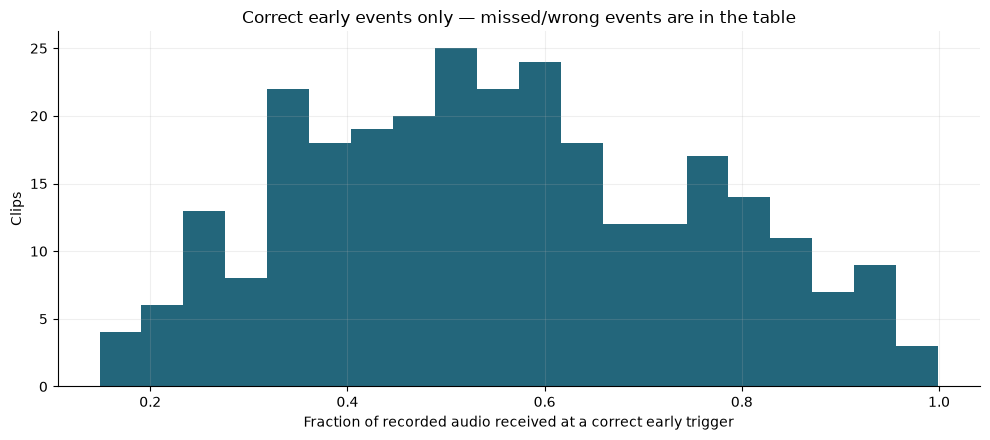

In [8]:
table(['Early event metric', 'Calibration', 'Final test'], [[key, cal['selected_early'].get(key), vcm['test']['early_fp32'].get(key)] for key in ['threshold','triggered','correct','wrong','precision','positive_trigger_recall','unknown_trigger_rate','median_correct_trigger_s','median_fraction_of_recording']])
display(Markdown('Selected routing policy: `' + json.dumps(bundle['routing']) + '`'))
from tinyvcm.evaluate import first_trigger
predictions = read_jsonl(ROOT / 'reports/predictions_vcm_test_fp32.jsonl')
fractions = []
for row in predictions:
    event = first_trigger(row['trace'], bundle['routing']['trigger_threshold'], labels)
    if event and event['vcm_command'] == row['gold']:
        fractions.append(event['audio_time_s']/row['duration'])
plt.hist(fractions, bins=20, color='#23667b')
plt.xlabel('Fraction of recorded audio received at a correct early trigger')
plt.ylabel('Clips'); plt.title('Correct early events only — missed/wrong events are in the table')
figure('early_trigger_fraction.png')

## 8. Noise and source microphone tests

The source distinguishes headset recordings from distant microphones. These are separate from Raspberry Pi capture. A fixed hash-selected subset is replayed unchanged, with 20 dB and 10 dB additive white noise. Thirty silence/noise-only waveforms test obvious nonspeech input. Simulated white noise is not household noise or room-response augmentation, and a clean-replay test cannot validate continuous listening in a home.

In [9]:
noise = read('noise_metrics.json')
table(['Condition', 'Clips', 'Raw accuracy', 'Positive recall after rejection', 'Unknown false accepts'], [[name, result['samples'], pct(result['accuracy']), pct(result['positive_recall_after_rejection']), result['unknown_false_accepts']] for name, result in noise.items() if isinstance(result, dict)])
table(['Source group', 'Clips', 'Raw accuracy', 'Macro F1'], [[name, result['samples'], pct(result['accuracy']), f"{result['macro_f1']:.3f}"] for name, result in vcm['test']['subgroups'].items()])
display(Markdown('The source metadata distinguishes native English from other native languages, not Philippine English. These groups must not be relabeled by accent.'))
open_set = read('open_set_metrics.json')
table(['Additional locked-threshold test', 'Clips', 'Passed final intent threshold', 'Early triggers'], [[name, result['samples'], result['passed_final_intent_threshold'], result['early_triggers']] for name, result in open_set['groups'].items()])
display(Markdown('Omitted command classes were excluded from the curated training/test label cohort. This additional test treats them as unsupported and applies the existing frozen thresholds. Its false accepts are reported separately; they must not be hidden inside the headline unknown rate. Explicit-negation cases are selected by source text, can include unrelated requests, and are not an exhaustive cancellation/compound-command test.'))

| Condition | Clips | Raw accuracy | Positive recall after rejection | Unknown false accepts |
|---|---|---|---|---|
| original | 194 | 70.6% | 12.6% | 0 |
| white_noise_20db | 194 | 53.6% | 6.9% | 0 |
| white_noise_10db | 194 | 33.0% | 3.4% | 0 |
| silence_and_noise_only | 30 | 33.3% | 0.0% | 0 |

| Source group | Clips | Raw accuracy | Macro F1 |
|---|---|---|---|
| headset | 1435 | 75.9% | 0.653 |
| distant | 1681 | 72.6% | 0.590 |
| native_english_metadata | 1277 | 72.2% | 0.574 |
| other_native_language_metadata | 1520 | 74.7% | 0.635 |
| unknown_language_metadata | 319 | 79.0% | 0.634 |

The source metadata distinguishes native English from other native languages, not Philippine English. These groups must not be relabeled by accent.

| Additional locked-threshold test | Clips | Passed final intent threshold | Early triggers |
|---|---|---|---|
| omitted_command_classes | 11 | 0 | 0 |
| explicit_negation_or_cancellation | 148 | 1 | 1 |

Omitted command classes were excluded from the curated training/test label cohort. This additional test treats them as unsupported and applies the existing frozen thresholds. Its false accepts are reported separately; they must not be hidden inside the headline unknown rate. Explicit-negation cases are selected by source text, can include unrelated requests, and are not an exhaustive cancellation/compound-command test.

## 9. Separate ASR results

WER is total word edits divided by reference words; CER uses characters. These corpus-level rates weight longer utterances by reference length. Exact match requires the entire normalized transcript to match. The full test is computed with the selected ASR checkpoint on GPU, using valid-length masking; export checks establish FP32 CPU ONNX logit parity, and the actual CPU voice suite compares FP32/INT8 decoding. No lexicon or language model is applied.

These are **full-utterance** results. Parameter-tail recognition is a different test: the predicted boundary may remove a word, and catalog names may be unseen. No gold-tail WER is claimed without verified timestamps. Punctuation, case, and accents are normalized for CTC; the English alphabet does not support arbitrary scripts.

In [10]:
table(['ASR test source', 'Clips', 'Reference words', 'WER', 'CER', 'Exact transcript match'], [[source, result['samples'], result['reference_words'], pct(result['wer']), pct(result['cer']), pct(result['exact_match'])] for source, result in asr.items() if isinstance(result, dict)])
table(['Variant on fixed voice suite', 'Full-audio WER', 'Tail ASR calls', 'Entity text retained in predicted tails', 'Reference-parser exact frames'], [[variant, pct(voice[variant]['full_audio_wer']), voice[variant]['tail_asr_invocations'], pct(voice[variant]['tail_entity_text_recall']), f"{voice[variant]['parser_reference_exact_frames']}/{voice[variant]['parser_reference_eligible']}"] for variant in ['fp32','int8']])
display(Markdown('Entity-tail recall uses all annotated entities in the fixed suite, including clips rejected before ASR; it is an end-to-end diagnostic. Missing triggers, truncated tails, ASR substitutions, and unrelated source entity types all affect it. Reference-parser frames are derived from human text plus the fixed example catalog, not a manually adjudicated semantic benchmark.'))

| ASR test source | Clips | Reference words | WER | CER | Exact transcript match |
|---|---|---|---|---|---|
| LibriSpeech | 2528 | 47112 | 41.3% | 14.4% | 1.5% |
| SLURP-real | 13019 | 83676 | 48.4% | 23.9% | 13.4% |

| Variant on fixed voice suite | Full-audio WER | Tail ASR calls | Entity text retained in predicted tails | Reference-parser exact frames |
|---|---|---|---|---|
| fp32 | 38.9% | 1 | 0.0% | 3/46 |
| int8 | 39.7% | 1 | 0.0% | 3/46 |

Entity-tail recall uses all annotated entities in the fixed suite, including clips rejected before ASR; it is an end-to-end diagnostic. Missing triggers, truncated tails, ASR substitutions, and unrelated source entity types all affect it. Reference-parser frames are derived from human text plus the fixed example catalog, not a manually adjudicated semantic benchmark.

## 10. Actual voice-command replay cases

The complete 3,116-recording VCM test cohort is also replayed through the actual CPU ONNX classifier, predicted slice, optional ASR, and parser in both precisions. The fixed example catalog is shared by all clips. Human text and curated gold intent are used only to produce a scoring reference with the deterministic parser; this is a silver reference, not manually adjudicated slot truth. Unresolvable reference names are counted as unscored, rather than silently removed from the dataset.

For a readable per-clip table, the fixed suite below selects up to six distinct paired-recording groups per VCM label by a stable ID hash, without looking at model confidence or correctness. Test transcripts are never inserted as runtime inputs or per-clip aliases. Detailed full-cohort cases are in `reports/predictions_joint.jsonl`; the smaller suite is in `reports/voice_test_results.jsonl`.

In [11]:
cases = read_jsonl(ROOT / 'reports/voice_test_results.jsonl')
table(['Full-cohort pipeline', 'Eligible silver references', 'Exact frames', 'Exact-frame rate', 'Unscored supported clips', 'Tail ASR calls', 'Accepted frames on unknown input'], [[variant, joint[variant]['reference_parser_eligible'], joint[variant]['exact_frames'], pct(joint[variant]['exact_frame_rate']), joint[variant]['supported_unscored'], joint[variant]['tail_asr_invocations'], joint[variant]['accepted_frames_on_unknown']] for variant in ['fp32','int8']])
table(['Reference speech', 'Gold intent', 'Final VCM label', 'Status', 'ASR parameter tail'], [[r['reference'], r['gold'], r['fp32']['result'].get('vcm_command','—'), r['fp32']['result']['status'], r['fp32']['result'].get('parameter_transcript','—')] for r in cases])
table(['Variant', 'Final status counts'], [[variant, json.dumps(voice[variant]['statuses'])] for variant in ['fp32','int8']])
stage_names = sorted(set(voice['fp32']['stage_counts']) | set(voice['int8']['stage_counts']))
table(['Observed stage/result', 'FP32 clips', 'INT8 clips'], [[name, voice['fp32']['stage_counts'].get(name,0), voice['int8']['stage_counts'].get(name,0)] for name in stage_names])
table(['Diagnostic comparison', 'FP32 exact frames', 'INT8 exact frames'], [['Measured VCM + predicted slice + ASR', voice['fp32']['parser_reference_exact_frames'], voice['int8']['parser_reference_exact_frames']], ['Gold intent supplied to parser + ASR of whole audio', voice['fp32']['oracle_intent_full_audio_exact_frames'], voice['int8']['oracle_intent_full_audio_exact_frames']]])
display(Markdown('The second row is a diagnostic control. It supplies the reference command only after independently transcribing the whole recording; it is not the production pipeline and has no gold parameter-boundary claim. Stage counts locate the first observed failure under this scoring rule, not a unique causal diagnosis.'))
display(Markdown('The following two examples are illustrative selections from that fixed suite; the full table above is the evidence.'))
accepted = next((r for r in cases if r['fp32']['result']['status']=='accepted'), cases[0])
failure = next((r for r in cases if r['gold']!='UNKNOWN' and r['fp32']['result']['status']!='accepted'), cases[-1])
for row in [accepted, failure]:
    display(Markdown('**' + row['reference'] + '** — `' + row['fp32']['result']['status'] + '`'))
    display(Audio(filename=str(ROOT / row['audio'])))
    display(row['fp32']['result'])

| Full-cohort pipeline | Eligible silver references | Exact frames | Exact-frame rate | Unscored supported clips | Tail ASR calls | Accepted frames on unknown input |
|---|---|---|---|---|---|---|
| fp32 | 1466 | 150 | 10.2% | 92 | 65 | 4 |
| int8 | 1466 | 147 | 10.0% | 92 | 62 | 4 |

| Reference speech | Gold intent | Final VCM label | Status | ASR parameter tail |
|---|---|---|---|---|
| help is to be sent only to jane | UNKNOWN | DATE_QUERY | rejected | — |
| lower the lights | BRIGHTNESS_DOWN | BRIGHTNESS_DOWN | rejected | — |
| find some smooth jazz for me | UNKNOWN | UNKNOWN | rejected | — |
| what time is it in new york now | TIME_QUERY | TIME_QUERY | accepted | — |
| swimming | UNKNOWN | UNKNOWN | rejected | — |
| what's sensational in time of india | TIME_QUERY | UNKNOWN | rejected | — |
| where seth lives | UNKNOWN | BRIGHTNESS_DOWN | rejected | — |
| what year did this song come out | UNKNOWN | UNKNOWN | rejected | — |
| turn on my playlist and play third song in the queue | MEDIA_PLAY | MEDIA_PLAY | rejected | — |
| how's the weather today | UNKNOWN | UNKNOWN | rejected | — |
| brighten the lights | BRIGHTNESS_UP | BRIGHTNESS_UP | rejected | — |
| what time is it | TIME_QUERY | TIME_QUERY | rejected | — |
| what time is it | TIME_QUERY | TIME_QUERY | accepted | — |
| what time are the hockey games tonight | TIME_QUERY | TIME_QUERY | rejected | — |
| play jingle bells | MEDIA_PLAY | MEDIA_PLAY | rejected | — |
| hey what time is it in london now | TIME_QUERY | TIME_QUERY | rejected | — |
| play bilando | MEDIA_PLAY | MEDIA_PLAY | needs_parameters | — |
| play some good song from my play list | MEDIA_PLAY | MEDIA_PLAY | rejected | — |
| turn down the lights to medium | BRIGHTNESS_DOWN | BRIGHTNESS_DOWN | rejected | — |
| i want a lower light | BRIGHTNESS_DOWN | BRIGHTNESS_DOWN | rejected | — |
| please dim the lights | BRIGHTNESS_DOWN | BRIGHTNESS_DOWN | rejected | — |
| resume the playback of a child called it | MEDIA_RESUME | MEDIA_RESUME | rejected | — |
| turn my lights down to a lower level of brightness | BRIGHTNESS_DOWN | POWER_OFF | rejected | — |
| shut off the socket | POWER_OFF | POWER_OFF | rejected | — |
| change the lights to dim | BRIGHTNESS_DOWN | COLOR_SET | needs_parameters | — |
| play the weekend | MEDIA_PLAY | MEDIA_PLAY | rejected | — |
| play any song by joe prsaise | MEDIA_PLAY | MEDIA_PLAY | accepted | whe song by joke r sace |
| make the bedroom lights red and the hall lights normal color please | COLOR_SET | COLOR_SET | rejected | — |
| change my light color to blue and please turn off the kitchen light | POWER_OFF | POWER_OFF | rejected | — |
| what day is the fifth | DATE_QUERY | UNKNOWN | rejected | — |
| what date is it | DATE_QUERY | DATE_QUERY | rejected | — |
| resume the song from the audiobook by the beatles | MEDIA_RESUME | MEDIA_RESUME | rejected | — |
| turn the lights off | POWER_OFF | POWER_OFF | rejected | — |
| please turn on the wemo plug socket | POWER_ON | POWER_ON | rejected | — |
| brighten the lights | BRIGHTNESS_UP | BRIGHTNESS_UP | rejected | — |
| turn off the lights in the bathroom | POWER_OFF | POWER_OFF | rejected | — |
| switch off the lights | POWER_OFF | BRIGHTNESS_UP | rejected | — |
| what day of the week is the twenty third of this month | DATE_QUERY | DATE_QUERY | rejected | — |
| turn lights off | POWER_OFF | BRIGHTNESS_DOWN | rejected | — |
| tell me today's date | DATE_QUERY | DATE_QUERY | accepted | — |
| what is the ten day forecast | DATE_QUERY | TIME_QUERY | rejected | — |
| brighten of lights in living room | BRIGHTNESS_UP | POWER_OFF | rejected | — |
| what's the date of the winter solstice two years from now | DATE_QUERY | DATE_QUERY | rejected | — |
| change the bedroom lights to green | COLOR_SET | COLOR_SET | rejected | — |
| change light color | COLOR_SET | DATE_QUERY | rejected | — |
| change the lights in the living room to green and red | COLOR_SET | COLOR_SET | rejected | — |
| make the bedroom lights red and the hall lights normal color please | COLOR_SET | UNKNOWN | rejected | — |
| brighten the light of hall | BRIGHTNESS_UP | POWER_OFF | rejected | — |
| i want the light to be a little more red ish | COLOR_SET | BRIGHTNESS_DOWN | rejected | — |
| resume the song from the audiobook by the beatles | MEDIA_RESUME | MEDIA_RESUME | rejected | — |
| resume the song from the audiobook by the beatles | MEDIA_RESUME | MEDIA_RESUME | rejected | — |
| raise the light | BRIGHTNESS_UP | BRIGHTNESS_UP | rejected | — |
| brighten the lights in the hallway | BRIGHTNESS_UP | BRIGHTNESS_UP | rejected | — |
| i want the status on my screen brightness | POWER_ON | UNKNOWN | rejected | — |
| turn on wemo | POWER_ON | POWER_ON | rejected | — |
| please turn on my balcony lights | POWER_ON | POWER_OFF | rejected | — |
| please turn on my balcony lights | POWER_ON | BRIGHTNESS_UP | rejected | — |
| i want the status on my screen brightness | POWER_ON | UNKNOWN | rejected | — |
| resume the song from the audiobook by the beatles | MEDIA_RESUME | MEDIA_RESUME | rejected | — |
| resume the playback of a child called it | MEDIA_RESUME | MEDIA_RESUME | rejected | — |

| Variant | Final status counts |
|---|---|
| fp32 | {"rejected": 54, "accepted": 4, "needs_parameters": 2} |
| int8 | {"rejected": 54, "accepted": 4, "needs_parameters": 2} |

| Observed stage/result | FP32 clips | INT8 clips |
|---|---|---|
| exact_reference_parser_frame | 3 | 3 |
| no_early_trigger_to_define_parameter_slice | 1 | 1 |
| unknown_or_low_confidence | 33 | 34 |
| unsupported_rejected | 6 | 6 |
| wrong_raw_intent | 16 | 15 |
| wrong_reference_parser_arguments | 1 | 1 |

| Diagnostic comparison | FP32 exact frames | INT8 exact frames |
|---|---|---|
| Measured VCM + predicted slice + ASR | 3 | 3 |
| Gold intent supplied to parser + ASR of whole audio | 36 | 36 |

...

The following two examples are illustrative selections from that fixed suite; the full table above is the evidence.

**what time is it in new york now** — `accepted`

{'vcm_command': 'TIME_QUERY',
 'confidence': 0.9959813533867197,
 'events': [{'stage': 'intent',
   'vcm_command': 'TIME_QUERY',
   'confidence': 0.9998374492775156,
   'audio_time_s': 1.015,
   'provisional': True}],
 'status': 'accepted',
 'command': {'action': 'GET_TIME', 'arguments': {}},
 'processing_ms': 31.784900005732197}

**lower the lights** — `rejected`

{'status': 'rejected',
 'reason': 'unknown_or_low_confidence',
 'vcm_command': 'BRIGHTNESS_DOWN',
 'confidence': 0.950401365413892,
 'processing_ms': 2.86469999991823}

### A retained-tail illustration

The example below is deliberately selected to show a correct early trigger. It illustrates the candidate buffer policy, not average accuracy. Shading starts 500 ms before the predicted intent event and continues to the recording end. Final confidence can still reject this candidate and skip ASR; an early event alone does not establish a completed handoff. Without a verified parameter timestamp, this picture cannot establish that the complete name survived the cut.

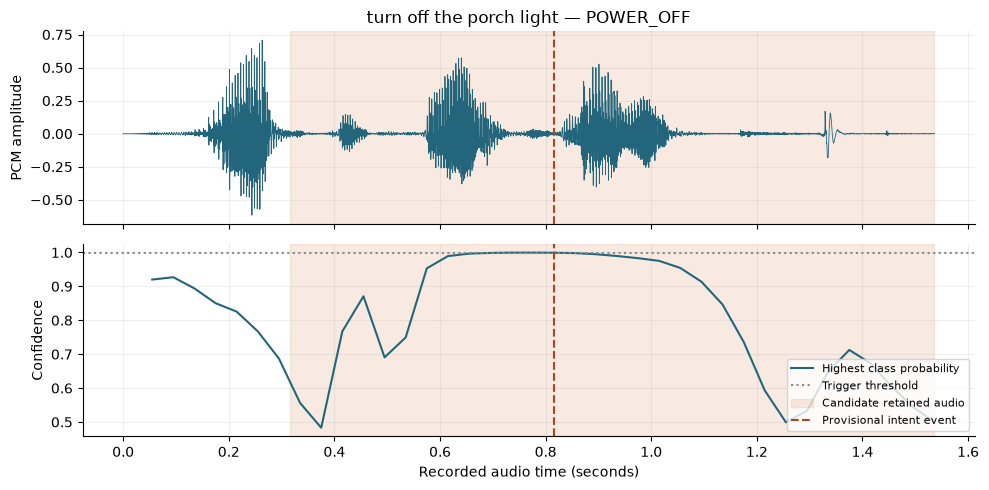

In [12]:
from tinyvcm.audio import load_audio
from tinyvcm.routing import PARAMETER_COMMANDS
illustration = None
for row in predictions:
    event = first_trigger(row['trace'], bundle['routing']['trigger_threshold'], labels)
    if event and event['vcm_command']==row['gold'] and row['gold'] in PARAMETER_COMMANDS:
        illustration = (row, event)
        break
if illustration:
    row, event = illustration
    pcm, _ = load_audio(ROOT / row['audio'])
    seconds = np.arange(len(pcm))/16000
    tail_start = max(0, event['audio_time_s'] - bundle['routing']['lookback_seconds'])
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    axes[0].plot(seconds, pcm, color='#23667b', linewidth=.6)
    axes[0].set_title(row['transcript'] + ' — ' + row['gold'])
    axes[0].set_ylabel('PCM amplitude')
    axes[1].plot([r[2] for r in row['trace']], [r[1] for r in row['trace']], color='#23667b', label='Highest class probability')
    axes[1].axhline(bundle['routing']['trigger_threshold'], color='#888888', linestyle=':', label='Trigger threshold')
    axes[1].set_ylabel('Confidence'); axes[1].set_xlabel('Recorded audio time (seconds)')
    for ax in axes:
        ax.axvspan(tail_start, row['duration'], color='#d8804a', alpha=.16, label='Candidate retained audio')
        ax.axvline(event['audio_time_s'], color='#a54722', linestyle='--', label='Provisional intent event')
    axes[1].legend(loc='lower right', fontsize=8)
    figure('parameter_handoff_example.png')

## 11. Philippine English evidence and limits

Ten public Speech Accent Archive readers with publisher-reported Philippine birthplace form an evaluation-only diagnostic. All read the same prompt. The normalized prompt is used for an agreement/error calculation, but it is **not a manually verified transcript of each recording**; misreadings or additions can inflate that rate. None of these recordings trained the models. The read paragraph does not contain the supported assistant commands, so short windows provide only an out-of-scope rejection diagnostic.

This is useful evidence of current behavior on a small accented sample. It does not establish Philippine-English command accuracy, balanced demographic coverage, natural conversational performance, or speaker-independent adaptation. A properly licensed, transcribed, speaker-partitioned command corpus is still needed for that claim. See [accent_data_audit.json](reports/accent_data_audit.json) for the public sources investigated.

In [13]:
table(['Diagnostic', 'Value'], [[key, value] for key, value in accent.items() if key != 'interpretation'])
accent_cases = read_jsonl(ROOT / 'reports/predictions_accent.jsonl')
table(['Public sample ID', 'Seconds', 'Word edits vs prompt', 'Reference words'], [[r['id'], f"{r['duration']:.1f}", r['word_errors_vs_prompt'], r['reference_words']] for r in accent_cases])

| Diagnostic | Value |
|---|---|
| speakers | 10 |
| total_audio_seconds | 247.9180625 |
| prompt_word_error_rate | 0.6101449275362318 |
| negative_vcm_windows | 37 |
| windows_passing_final_intent_threshold | 0 |
| positive_command_samples | 0 |
| training_use | False |

| Public sample ID | Seconds | Word edits vs prompt | Reference words |
|---|---|---|---|
| saa/english140 | 19.4 | 32 | 69 |
| saa/english348 | 19.8 | 42 | 69 |
| saa/tagalog1 | 23.2 | 53 | 69 |
| saa/tagalog2 | 29.1 | 44 | 69 |
| saa/tagalog4 | 28.6 | 45 | 69 |
| saa/tagalog5 | 28.5 | 36 | 69 |
| saa/tagalog6 | 21.1 | 41 | 69 |
| saa/tagalog7 | 27.3 | 39 | 69 |
| saa/tagalog8 | 27.0 | 47 | 69 |
| saa/tagalog9 | 23.7 | 42 | 69 |

## 12. Quantization, runtime, and hardware evidence

ONNX Runtime static quantization uses signed INT8 weights/activations in QDQ form, with per-channel convolution weights. Only Conv/Gemm/MatMul operators are targeted; normalization and other operations remain floating point. Calibration uses 200 training examples, with stateful chunk samples for the streaming model. Threshold calibration and final tests are excluded from quantization-range fitting. See [ONNX Runtime quantization documentation](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html) for the method.

FP32 remains the default. File-size reduction does not guarantee CPU acceleration, particularly with depthwise convolutions and mixed floating-point operations. The following timings are **measured Windows CPU replay**, using the actual host and thread counts shown. They include feature extraction, but exclude live microphone scheduling, endpoint latency, and sustained thermal behavior. These measurements come from the development workstation; other desktop activity was not controlled.

In [14]:
benchmarks = {variant: read('benchmark_windows_'+variant+'.json') for variant in ['fp32','int8']}
display(benchmarks['fp32']['host'])
rows = []
for variant, result in benchmarks.items():
    assert result['is_raspberry_pi4'] is False
    for path, values in result['measurements'].items():
        rows.append([variant, path, values['runs'], f"{values['p50_ms']:.2f}", f"{values['p95_ms']:.2f}", f"{values['p95_rtf']:.3f}"])
table(['Variant', 'Path', 'Runs', 'Median ms', '95th pct ms', '95th pct real-time factor'], rows)
table(['Variant', 'Peak process RSS MiB', 'Threads'], [[variant, f"{result['process_peak_rss_bytes']/2**20:.1f}", result['threads']] for variant,result in benchmarks.items()])
display(read('runtime_smoke.json'))

{'system': 'Windows',
 'release': '11',
 'machine': 'AMD64',
 'processor': 'Intel64 Family 6 Model 183 Stepping 1, GenuineIntel',
 'cpu_count': 32,
 'python': '3.12.13',
 'onnxruntime': '1.30.0'}

| Variant | Path | Runs | Median ms | 95th pct ms | 95th pct real-time factor |
|---|---|---|---|---|---|
| fp32 | vcm_whole_file | 120 | 2.17 | 4.05 | 0.001 |
| fp32 | vcm_stream_replay | 120 | 17.38 | 33.36 | 0.009 |
| fp32 | asr_whole_file | 120 | 4.14 | 6.92 | 0.002 |
| fp32 | routed_pipeline | 120 | 2.53 | 16.03 | 0.007 |
| int8 | vcm_whole_file | 120 | 1.67 | 2.73 | 0.001 |
| int8 | vcm_stream_replay | 120 | 17.56 | 30.87 | 0.009 |
| int8 | asr_whole_file | 120 | 2.67 | 4.36 | 0.001 |
| int8 | routed_pipeline | 120 | 1.76 | 14.85 | 0.008 |

| Variant | Peak process RSS MiB | Threads |
|---|---|---|
| fp32 | 151.8 | 2 |
| int8 | 152.1 | 2 |

{'status': 'passed',
 'host': 'Windows-11-10.0.26200-SP0',
 'python': '3.12.13',
 'executable': 'C:\\Users\\SCL-Jus\\Documents\\Grad\\smart-speaker\\model\\.runtime-venv\\Scripts\\python.exe',
 'pytorch_installed': False,
 'pytorch_imported': False,
 'packages': {'numpy': '2.5.3',
  'scipy': '1.18.1',
  'einops': '0.8.2',
  'onnxruntime': '1.30.0',
  'soundfile': '0.14.0',
  'sounddevice': '0.5.6'},
 'voice_inference_cases': 8,
 'cli_predict_calls': [{'asr': 'off',
   'result': {'status': 'rejected',
    'reason': 'unknown_or_low_confidence',
    'vcm_command': 'MEDIA_PLAY',
    'confidence': 0.9215626742024536,
    'processing_ms': 4.60709999606479}},
  {'asr': 'on',
   'result': {'status': 'rejected',
    'reason': 'unknown_or_low_confidence',
    'vcm_command': 'MEDIA_PLAY',
    'confidence': 0.9215626742024536,
    'processing_ms': 4.242100003466476}}],
 'device_enumeration_succeeded': True,
 'evidence': 'Fresh venv installed only requirements-runtime.lock; both FP32 and INT8 model

## 13. Verification and Raspberry Pi handoff

Automated contract tests cover future-independent VCM predictions, explicit streaming caches, chunked feature parity, real resampling, CTC repeated letters, masked ASR batch padding, fixed action semantics, ambiguous target rejection, microphone index/name/backend resolution, disabled-ASR operation, and runtime imports with PyTorch unavailable. They complement the held-out audio experiments; unit tests alone do not establish speech accuracy.

The CLI was exercised on this Windows host, including device enumeration and a fresh runtime-only environment. Physical microphone speech capture, unplug/reconnect behavior, Pi CPU/RAM, and thermal limits have not been validated on a Raspberry Pi. Input indices are machine-specific; select a microphone after listing devices on the board.

```bash
# On a 64-bit Raspberry Pi OS, from model/
sudo apt-get install python3-venv libportaudio2 libsndfile1
python3 -m venv .venv
.venv/bin/python -m pip install -r requirements-runtime.lock
.venv/bin/python -m pip install --no-deps -e .
.venv/bin/python -m tinyvcm devices
.venv/bin/python -m tinyvcm listen --mic "USB" --asr on --catalog configs/catalog.example.json
.venv/bin/python -m tinyvcm listen --config configs/pi4.toml --mic 2 --asr off
.venv/bin/python scripts/benchmark.py --variant fp32 --threads 2 --output reports/benchmark_pi4_fp32.json
```

Microphone selection accepts an index or unique name substring, with optional `--host-api`, `--channel`, and `--capture-rate`. CLI options override TOML settings. Capture tries 16 kHz and otherwise resamples a supported native rate; it never relabels audio sampled at another rate. Overflow or an eight-second timeout invalidates the utterance.

In [15]:
print((ROOT / 'logs/contract_tests.log').read_text(encoding='utf-8').strip())
print('Windows microphone enumeration (not Raspberry Pi):')
print((ROOT / 'reports/microphones_windows.txt').read_text(encoding='utf-8').strip())
print('ARM64 Linux/Python 3.11 binary dependency resolution (installation/hardware not tested):')
print((ROOT / 'reports/pi_dependency_resolution.txt').read_text(encoding='utf-8').strip())
gates = [
    ['Independent VCM and ASR training completed', all(c['status']=='complete' for c in completions.values())],
    ['VCM below 1 million parameters', bundle['vcm']['parameters'] < 1_000_000],
    ['ASR below 5 million parameters', bundle['asr']['parameters'] < 5_000_000],
    ['Supported-label whole-utterance accuracy at least the proposed 95%', supported_accuracy >= .95],
    ['Unknown final false-accept rate at most 1%', test['unknown_false_accept_rate'] <= .01],
    ['Supported-command recall after rejection at least 80%', test['positive_recall_after_rejection'] >= .8],
    ['Verified parameter boundary model', False],
    ['At most 300 ms delay from an annotated sufficient cue', False],
    ['At least 99% verified first-parameter onset retention', False],
    ['At least 90% exact supported slots on gold parameter tails', False],
    ['At least 90% exact complete frames against the parser reference', joint['fp32']['exact_frame_rate'] >= .9],
    ['At least 80% exact frames under a defined noisy pipeline test', False],
    ['Audio tests for held-out names at catalog sizes 25/100/500', False],
    ['Philippine-English supported-command benchmark', False],
    ['Physical Raspberry Pi 4 validation', False],
    ['Pi 4 microphone reconnect and 30-minute thermal/capture soak', False],
]
table(['Milestone / proposed release gate', 'Outcome'], [[name, 'PASS' if ok else 'NOT MET / NOT VALIDATED'] for name, ok in gates])
display(Markdown('The original clean-prefix, gold-slot, and timing targets require annotations that this run does not have. Whole-utterance/silver-parser results are reported as proxies and cannot establish those missing claims. The proposed complete-frame target is therefore only provisionally compared above; the full manually adjudicated target remains unvalidated.'))

................................                                         [100%]
32 passed in 3.31s
Windows microphone enumeration (not Raspberry Pi):
0 Microsoft Sound Mapper - Input, MME (2 in, 0 out)
>  1 Microphone (Steam Streaming Mic, MME (8 in, 0 out)
   2 Microphone (PicoStreamingMicrop, MME (2 in, 0 out)
   3 Microphone Array (Pico Streamin, MME (2 in, 0 out)
   4 Microsoft Sound Mapper - Output, MME (0 in, 2 out)
<  5 Digital Audio (S/PDIF) (High De, MME (0 in, 2 out)
   6 Speakers (Pico Streaming Speake, MME (0 in, 2 out)
   7 Speakers (Steam Streaming Micro, MME (0 in, 8 out)
   8 Speakers (Steam Streaming Speak, MME (0 in, 8 out)
   9 Primary Sound Capture Driver, Windows DirectSound (2 in, 0 out)
  10 Microphone (Steam Streaming Microphone), Windows DirectSound (8 in, 0 out)
  11 Microphone (PicoStreamingMicrophone), Windows DirectSound (2 in, 0 out)
  12 Microphone Array (Pico Streaming Speaker), Windows DirectSound (2 in, 0 out)
  13 Primary Sound Driver, Windows DirectS

| Milestone / proposed release gate | Outcome |
|---|---|
| Independent VCM and ASR training completed | PASS |
| VCM below 1 million parameters | PASS |
| ASR below 5 million parameters | PASS |
| Supported-label whole-utterance accuracy at least the proposed 95% | NOT MET / NOT VALIDATED |
| Unknown final false-accept rate at most 1% | PASS |
| Supported-command recall after rejection at least 80% | NOT MET / NOT VALIDATED |
| Verified parameter boundary model | NOT MET / NOT VALIDATED |
| At most 300 ms delay from an annotated sufficient cue | NOT MET / NOT VALIDATED |
| At least 99% verified first-parameter onset retention | NOT MET / NOT VALIDATED |
| At least 90% exact supported slots on gold parameter tails | NOT MET / NOT VALIDATED |
| At least 90% exact complete frames against the parser reference | NOT MET / NOT VALIDATED |
| At least 80% exact frames under a defined noisy pipeline test | NOT MET / NOT VALIDATED |
| Audio tests for held-out names at catalog sizes 25/100/500 | NOT MET / NOT VALIDATED |
| Philippine-English supported-command benchmark | NOT MET / NOT VALIDATED |
| Physical Raspberry Pi 4 validation | NOT MET / NOT VALIDATED |
| Pi 4 microphone reconnect and 30-minute thermal/capture soak | NOT MET / NOT VALIDATED |

The original clean-prefix, gold-slot, and timing targets require annotations that this run does not have. Whole-utterance/silver-parser results are reported as proxies and cannot establish those missing claims. The proposed complete-frame target is therefore only provisionally compared above; the full manually adjudicated target remains unvalidated.

## 14. Conclusions and next experiment

The deliverable is a complete, reproducible baseline with trained weights and actual voice-test results. The small VCM can operate independently, and a separately trained ASR can fill parameter text. Model files fit comfortably below the chosen parameter budgets. The microphone can be selected through the CLI.

The current model is **not ready for reliable everyday command control**. Low supported-command recall, missing intents, early-trigger mistakes, and uncertain parameter slicing are material limitations. The exact counts above should guide the next phase:

1. Annotate distinguishable command prefixes and parameter onset on existing public human recordings. Train/evaluate readiness and boundary heads without using ASR as a VCM dependency.
2. Increase scarce command examples and review hard negatives, cancellations, compounds, and parameter-first requests. Use a new locked speaker-disjoint evaluation before claiming generalization.
3. Train the ASR on verified parameter crops; evaluate unseen catalog names, slot exact match, and calibration under predicted boundaries.
4. Acquire and partition suitable Philippine-English command audio. Keep the small read-prompt diagnostic distinct.
5. Run the supplied benchmark and live microphone tests on Pi 4, then choose FP32/INT8 by board measurements. Tune endpointing from recorded, permissioned test sessions rather than assuming desktop replay proves deployment.

## 15. Reproduction and artifact map

See [README.md](README.md) for acquisition, training, export, evaluation, and Pi commands. `scripts/build_report.py` executes this report from the saved artifacts without retraining. Downloaded audio/features live under `data/`; weights and optimizer states under `runs/`; deployable ONNX models and hashes under `artifacts/tinyvcm/`; metrics, figures, and individual predictions under `reports/`. Large generated artifacts are intentionally local and excluded from Git.

Reproducing this run requires the pinned source ledgers, dataset licenses, adequate storage, and a CUDA training environment. A fresh runtime-only environment was checked separately. The environment snapshot below records what actually ran; the runtime lock has its own resolved versions. Seed 17 fixes initialization and data-order generators, but CUDA kernels are not forced into bitwise deterministic mode; resumed runs do not promise identical RNG continuation. No previous ME2 model metrics or weights were reused.

In [16]:
display(read('environment.json'))
assert all(cell['status']=='complete' for cell in completions.values())
print('Report generated from completed training runs and recorded tests.')

{'recorded_utc': '2026-09-15T10:22:51Z',
 'python': '3.12.13 (main, Jul 23 2026, 14:44:57) [MSC v.1944 64 bit (AMD64)]',
 'executable': 'C:\\Users\\SCL-Jus\\Documents\\Grad\\ME2\\.venv\\Scripts\\python.exe',
 'system': 'Windows',
 'release': '11',
 'processor': 'Intel64 Family 6 Model 183 Stepping 1, GenuineIntel',
 'machine': 'AMD64',
 'cpu_count': 32,
 'packages': {'torch': '2.13.0+cu130',
  'numpy': '2.5.3',
  'scipy': '1.18.1',
  'einops': '0.8.2',
  'soundfile': '0.14.0',
  'sounddevice': '0.5.6',
  'onnx': '1.22.0',
  'onnxruntime': '1.30.0',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0',
  'matplotlib': '3.11.2',
  'pytest': '9.1.1',
  'ipykernel': '7.3.0'},
 'torch_cuda': '13.0',
 'gpu': 'NVIDIA GeForce RTX 4080 SUPER',
 'gpu_memory_bytes': 17170956288,
 'runtime_lock_note': 'requirements-runtime.lock is resolved separately; the fresh runtime-only smoke environment is tested and recorded in runtime_smoke.json',
 'local_optional_dependencies': {'pyarrow': '25.0.1 in model/.deps

Report generated from completed training runs and recorded tests.
